<a href="https://colab.research.google.com/github/jyryu3161/2026CADD/blob/main/week4_cancer_TNBC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 4. TNBC-selective target discovery with DepMap

이 튜토리얼의 목표는 **DepMap CRISPR gene dependency probability**를 이용하여 유방암 세포주 중 **TNBC (triple-negative breast cancer)** 에서 상대적으로 선택적인 dependency를 보이는 유전자를 찾는 것입니다.

학습 목표:
1. Central Limit Theorem과 두 집단 비교의 개념 복습
2. DepMap `Model.csv`와 `CRISPRGeneDependency.csv` 이해
3. Breast cancer 모델을 TNBC vs non-TNBC로 annotation
4. 각 유전자에 대해 두 집단의 dependency probability 비교
5. Welch's t-test + Benjamini-Hochberg FDR로 후보 타깃 선별
6. Volcano plot, heatmap으로 결과 해석

> **중요:** 이 노트북의 TNBC label은 수업용 curated annotation입니다. 실제 연구/논문에서는 각 cell line의 ER/PR/HER2 상태를 최신 source로 재확인해야 합니다. `Basal-like`와 `TNBC`는 동일한 개념이 아닙니다.


# 3. DepMap datasets

사용 데이터:
- `Model.csv`: DepMap model metadata
- `CRISPRGeneDependency.csv`: Post-Chronos gene dependency probability (0–1)

Dependency probability는 p-value가 아니라, 해당 세포주가 특정 유전자에 **dependent일 확률**에 가까운 score입니다. 일반적으로 값이 1에 가까울수록 dependency가 강합니다.

이 실습에서는 mutation 정보가 아니라 **암 subtype 자체(TNBC vs non-TNBC)** 를 비교합니다.


In [ ]:
# 수업용 데이터 다운로드
!wget --no-check-certificate "https://www.dropbox.com/scl/fi/1drlmzwxd0fn1gekeoxke/lec05_data.zip?rlkey=2sr04tx67z1y6om0b51huyahd&st=aij7fene&dl=0" -O "lec5_data.zip"
!unzip lec5_data.zip



--2026-09-21 13:01:03--  https://www.dropbox.com/scl/fi/1drlmzwxd0fn1gekeoxke/lec05_data.zip?rlkey=2sr04tx67z1y6om0b51huyahd&st=aij7fene&dl=0
Resolving www.dropbox.com (www.dropbox.com)... 162.125.5.18, 2620:100:601d:18::a27d:512
Connecting to www.dropbox.com (www.dropbox.com)|162.125.5.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://uc5a62fbb161bded36083def4122.dl.dropboxusercontent.com/cd/0/inline/DIgW8CMepJe8bhK5ItewpIz51CXLRjXecun_TqQccHOOrUF9gJtJXdTMOgNeZiT0iYyjZTcAFb1bnf-YQOYm4HA1BtO0JkFi_fiU3CsX-hBVxdvpt1VrITn0kqyNbb2lWczhbMzPV5jzLmknTc0iwBrv/file# [following]
--2026-09-21 13:01:04--  https://uc5a62fbb161bded36083def4122.dl.dropboxusercontent.com/cd/0/inline/DIgW8CMepJe8bhK5ItewpIz51CXLRjXecun_TqQccHOOrUF9gJtJXdTMOgNeZiT0iYyjZTcAFb1bnf-YQOYm4HA1BtO0JkFi_fiU3CsX-hBVxdvpt1VrITn0kqyNbb2lWczhbMzPV5jzLmknTc0iwBrv/file
Resolving uc5a62fbb161bded36083def4122.dl.dropboxusercontent.com (uc5a62fbb161bded36083def4122.dl.dropboxusercontent.com)... 1

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
cellline_df = pd.read_csv("./Model.csv")
ess_prob_df = pd.read_csv("./CRISPRGeneDependency.csv", index_col=0)

print('Model metadata:', cellline_df.shape)
print('Dependency matrix:', ess_prob_df.shape)
display(cellline_df.head())
display(ess_prob_df.iloc[:5, :5])


Model metadata: (2105, 47)
Dependency matrix: (1178, 17916)


,ModelID,PatientID,CellLineName,StrippedCellLineName,DepmapModelType,OncotreeLineage,OncotreePrimaryDisease,OncotreeSubtype,OncotreeCode,PatientSubtypeFeatures,...,EngineeredModelDetails,CulturedResistanceDrug,PublicComments,CCLEName,HCMIID,ModelAvailableInDbgap,ModelSubtypeFeatures,WTSIMasterCellID,SangerModelID,COSMICID
0,ACH-000001,PT-gj46wT,NIH:OVCAR-3,NIHOVCAR3,HGSOC,Ovary/Fallopian Tube,Ovarian Epithelial Tumor,High-Grade Serous Ovarian Cancer,HGSOC,NaN,...,NaN,NaN,NaN,NIHOVCAR3_OVARY,NaN,Available in SRA,NaN,2201.0,SIDM00105,905933.0
1,ACH-000002,PT-5qa3uk,HL-60,HL60,AML,Myeloid,Acute Myeloid Leukemia,Acute Myeloid Leukemia,AML,"TP53(del), CDKN2A and NRAS mutations [PubMed=2...",...,NaN,NaN,NaN,HL60_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,NaN,Available in SRA,NaN,55.0,SIDM00829,905938.0
2,ACH-000003,PT-puKIyc,CACO2,CACO2,COAD,Bowel,Colorectal Adenocarcinoma,Colon Adenocarcinoma,COAD,NaN,...,NaN,NaN,NaN,CACO2_LARGE_INTESTINE,NaN,Available in SRA,NaN,NaN,SIDM00891,NaN
3,ACH-000004,PT-q4K2cp,HEL,HEL,AML,Myeloid,Acute Myeloid Leukemia,Acute Myeloid Leukemia,AML,"JAK2 and TP53 mutations,",...,NaN,NaN,NaN,HEL_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,NaN,Available in SRA,NaN,783.0,SIDM00594,907053.0
4,ACH-000005,PT-q4K2cp,HEL 92.1.7,HEL9217,AML,Myeloid,Acute Myeloid Leukemia,Acute Myeloid Leukemia,AML,JAK2 and TP53 mutations,...,NaN,NaN,NaN,HEL9217_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,NaN,Available in SRA,NaN,NaN,SIDM00593,NaN


,A1BG (1),A1CF (29974),A2M (2),A2ML1 (144568),A3GALT2 (127550)
ACH-000001,0.065668,0.015635,0.018194,0.080116,0.027776
ACH-000004,0.025267,0.050137,0.050000,0.032089,0.028282
ACH-000005,0.076913,0.019836,0.006571,0.011018,0.059735
ACH-000007,0.031522,0.047508,0.006059,0.005069,0.016260
ACH-000009,0.039600,0.116588,0.016466,0.013633,0.013288


# 4. Breast cancer 모델 추출

DepMap metadata에서 `OncotreeCode == "BRCA"`인 모델을 breast cancer로 선택합니다.


In [ ]:
breast_cancer_cell_df = cellline_df[cellline_df['OncotreeCode'].eq('BRCA')].copy()

# 실제 dependency matrix에 존재하는 모델만 유지
breast_cancer_cell_df = breast_cancer_cell_df[
    breast_cancer_cell_df['ModelID'].isin(ess_prob_df.index)
].copy()

print(f'Breast cancer models with CRISPR dependency data: {len(breast_cancer_cell_df)}')

# Model.csv 버전에 따라 cell-line name column 이름이 다를 수 있으므로 자동 탐색
name_candidates = ['CellLineName', 'StrippedCellLineName', 'ModelName', 'CCLEName']
name_col = next((c for c in name_candidates if c in breast_cancer_cell_df.columns), None)
if name_col is None:
    raise ValueError(f'Cell-line name column을 찾지 못했습니다. 사용 가능한 columns: {list(breast_cancer_cell_df.columns)}')

print('Cell-line name column:', name_col)
display(breast_cancer_cell_df[['ModelID', name_col]].head(20))


Breast cancer models with CRISPR dependency data: 19
Cell-line name column: CellLineName


,ModelID,CellLineName
15,ACH-000017,SK-BR-3
17,ACH-000019,MCF7
26,ACH-000028,KPL-1
210,ACH-000212,CAL-120
246,ACH-000248,AU565
256,ACH-000258,Du4475
350,ACH-000352,HCC1428
764,ACH-000768,MDA-MB-231
845,ACH-000849,MDA-MB-468
852,ACH-000856,CAL-51


# 5. TNBC annotation 추가

DepMap의 breast lineage metadata만으로 모든 모델의 임상적 TNBC 상태를 직접 정의하기 어렵기 때문에, 수업에서는 문헌에 반복적으로 등장하는 TNBC cell line을 curated list로 지정합니다.

대표적으로 BL1/BL2/M/MSL/LAR 계열의 TNBC 모델을 포함합니다. 세부 subtype은 연구마다 일부 차이가 있으므로 **TNBC vs non-TNBC 비교가 주 분석**, 세부 TNBC subtype은 참고용입니다.

참고 문헌:
- Lehmann 계열 TNBC subtype 재평가: https://pmc.ncbi.nlm.nih.gov/articles/PMC7192374/
- TNBC cell-line panel 예시: https://pmc.ncbi.nlm.nih.gov/articles/PMC6746778/

> **주의:** 아래에서 `Other_breast`는 “확실한 non-TNBC receptor-confirmed cohort”가 아니라, 이 curated TNBC list에 포함되지 않은 DepMap breast models입니다. 연구용 분석에서는 ER/PR/HER2 annotation을 추가하여 HR+/HER2+를 명시적으로 정의하세요.


In [ ]:
# 이름 비교를 위한 정규화 함수
def normalize_cell_line_name(x):
    return (str(x).upper()
            .replace('-', '')
            .replace('_', '')
            .replace(' ', '')
            .replace('.', ''))

# 수업용 curated TNBC annotation
# subtype은 참고용이며 문헌/분류법에 따라 달라질 수 있음
tnbc_annotation = {
    'HCC1599': 'BL-like',
    'HCC1937': 'BL1',
    'HCC1143': 'BL1',
    'MDAMB468': 'BL1/BL2',
    'HCC38': 'BL1',
    'HCC70': 'BL2',
    'HCC1806': 'BL2',
    'HCC1187': 'IM/BL2',
    'DU4475': 'IM/BL1',
    'BT549': 'M',
    'HS578T': 'MSL',
    'MDAMB231': 'MSL/BL2',
    'MDAMB436': 'MSL',
    'MDAMB157': 'MSL/LAR',
    'BT20': 'BL2/LAR',
    'HCC1395': 'TNBC',
    'SUM149PT': 'BL2',
    'SUM159PT': 'MSL/BL2',
    'SUM185PE': 'LAR',
    'SUM229PE': 'TNBC',
    'SUM52PE': 'TNBC',
    'HCC2157': 'BL1',
    'HCC3153': 'BL1/M',
}

breast_cancer_cell_df['NormalizedName'] = breast_cancer_cell_df[name_col].map(normalize_cell_line_name)
breast_cancer_cell_df['TNBC'] = breast_cancer_cell_df['NormalizedName'].isin(tnbc_annotation)
breast_cancer_cell_df['TNBC_subtype'] = breast_cancer_cell_df['NormalizedName'].map(tnbc_annotation)
breast_cancer_cell_df['SubtypeGroup'] = np.where(
    breast_cancer_cell_df['TNBC'], 'TNBC', 'Other_breast'
)

summary = breast_cancer_cell_df['SubtypeGroup'].value_counts().rename_axis('Group').to_frame('N')
display(summary)
display(
    breast_cancer_cell_df[['ModelID', name_col, 'SubtypeGroup', 'TNBC_subtype']]
    .sort_values(['SubtypeGroup', name_col])
    .reset_index(drop=True)
)


,N
Group,
Other_breast,12
TNBC,7


,ModelID,CellLineName,SubtypeGroup,TNBC_subtype
0,ACH-000248,AU565,Other_breast,NaN
1,ACH-000212,CAL-120,Other_breast,NaN
2,ACH-000856,CAL-51,Other_breast,NaN
3,ACH-000352,HCC1428,Other_breast,NaN
4,ACH-000028,KPL-1,Other_breast,NaN
5,ACH-000019,MCF7,Other_breast,NaN
6,ACH-000934,MDA-MB-361,Other_breast,NaN
7,ACH-000876,MDA-MB-415,Other_breast,NaN
8,ACH-000910,MDA-MB-453,Other_breast,NaN
9,ACH-002179,OCUB-M,Other_breast,NaN


## 확인: 어떤 cell line이 비교에 들어가는가?

TNBC annotation이 실제 DepMap 이름과 잘 매칭되었는지 반드시 확인합니다. 이름 표기 차이로 빠진 모델이 있으면 curated dictionary에 추가할 수 있습니다.


In [ ]:
tnbc_ids = breast_cancer_cell_df.loc[breast_cancer_cell_df['TNBC'], 'ModelID'].tolist()
other_ids = breast_cancer_cell_df.loc[~breast_cancer_cell_df['TNBC'], 'ModelID'].tolist()

print('TNBC N =', len(tnbc_ids))
print('Other breast N =', len(other_ids))
print('Total N =', len(tnbc_ids) + len(other_ids))

print('\nTNBC models:')
display(breast_cancer_cell_df.loc[breast_cancer_cell_df['TNBC'], ['ModelID', name_col, 'TNBC_subtype']])


TNBC N = 7
Other breast N = 12
Total N = 19

TNBC models:


,ModelID,CellLineName,TNBC_subtype
256,ACH-000258,Du4475,IM/BL1
764,ACH-000768,MDA-MB-231,MSL/BL2
845,ACH-000849,MDA-MB-468,BL1/BL2
1215,ACH-001391,SUM-159PT,MSL/BL2
1216,ACH-001392,SUM-185PE,LAR
1218,ACH-001394,SUM-229PE,TNBC
1220,ACH-001396,SUM-52PE,TNBC


# 6. TNBC-selective gene dependency 분석

각 gene에 대해 다음을 계산합니다.

- `TNBC_mean`: TNBC에서 평균 dependency probability
- `Other_mean`: 나머지 breast model에서 평균 dependency probability
- `Delta_dependency = TNBC_mean - Other_mean`
- `TNBC_dep_fraction`: TNBC 중 dependency probability > 0.5인 비율
- `Other_dep_fraction`: 다른 breast model 중 dependency probability > 0.5인 비율
- Welch's t-test p-value
- Benjamini-Hochberg FDR

**양의 Delta_dependency가 클수록 TNBC에서 상대적으로 선택적인 dependency**를 의미합니다.


In [ ]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests
import numpy as np
import pandas as pd
import tqdm

def compare_dependency_by_group(dependency_df, group_a_ids, group_b_ids):

    # 실제 dependency matrix에 존재하는 모델만 사용
    group_a_ids = [x for x in group_a_ids if x in dependency_df.index]
    group_b_ids = [x for x in group_b_ids if x in dependency_df.index]

    rows = []

    for gene in tqdm.tqdm(dependency_df.columns):

        a = dependency_df.loc[group_a_ids, gene].dropna().astype(float)
        b = dependency_df.loc[group_b_ids, gene].dropna().astype(float)

        if len(a) < 3 or len(b) < 3:
            continue

        # 그룹 간 비교
        t_stat, p_value = ttest_ind(
            a,
            b,
            equal_var=False,
            nan_policy='omit'
        )

        rows.append({
            'Gene': gene,
            'TNBC_N': len(a),
            'Other_N': len(b),

            'TNBC_mean': a.mean(),
            'Other_mean': b.mean(),

            'Delta_dependency': a.mean() - b.mean(),

            'TNBC_dep_fraction': (a > 0.5).mean(),
            'Other_dep_fraction': (b > 0.5).mean(),

            't_stat': t_stat,
            'p_value': p_value,
        })

    result = pd.DataFrame(rows)

    # ------------------------------------
    # FDR correction: finite p-values only
    # ------------------------------------
    result['FDR'] = np.nan

    valid = np.isfinite(result['p_value'])

    result.loc[valid, 'FDR'] = multipletests(
        result.loc[valid, 'p_value'],
        method='fdr_bh'
    )[1]

    return (
        result
        .sort_values(
            ['FDR', 'Delta_dependency'],
            ascending=[True, False],
            na_position='last'
        )
        .reset_index(drop=True)
    )


result_df = compare_dependency_by_group(
    ess_prob_df,
    tnbc_ids,
    other_ids
)

result_df.head(20)

  0%|          | 62/17916 [00:01<06:00, 49.48it/s]/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
  7%|▋         | 1287/17916 [00:09<00:55, 297.96it/s]/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
 13%|█▎        | 2340/17916 [00:13<00:58, 265.79it/s]/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypote

,Gene,TNBC_N,Other_N,TNBC_mean,Other_mean,Delta_dependency,TNBC_dep_fraction,Other_dep_fraction,t_stat,p_value,FDR
0,OR51T1 (401665),7,10,0.043988,0.016608,0.027380,0.000000,0.000000,5.373175,0.000094,0.833428
1,ATP5PF (522),7,12,0.173676,0.530133,-0.356457,0.000000,0.666667,-5.196124,0.000084,0.833428
2,FAM50A (9130),7,12,0.648029,0.218087,0.429942,0.714286,0.083333,2.667741,0.022679,0.862511
3,PRKRA (8575),7,12,0.884148,0.474464,0.409684,0.857143,0.333333,4.299063,0.001095,0.862511
4,EFR3A (23167),7,12,0.511615,0.115292,0.396323,0.571429,0.083333,2.746803,0.026250,0.862511
5,CHMP4B (128866),7,12,0.812436,0.418054,0.394381,0.857143,0.416667,2.098969,0.053199,0.862511
6,PGGT1B (5229),7,12,0.753512,0.360001,0.393511,0.857143,0.333333,3.396416,0.004608,0.862511
7,SYS1 (90196),7,12,0.901043,0.519386,0.381656,0.857143,0.500000,2.823912,0.011722,0.862511
8,SPRYD4 (283377),7,12,0.694578,0.326174,0.368404,0.857143,0.166667,4.932977,0.000201,0.862511
9,UBIAD1 (29914),7,12,0.611347,0.262758,0.348589,0.428571,0.166667,2.823362,0.019486,0.862511


# 7. TNBC-selective candidate target 선별

수업에서는 다음과 같은 **해석 가능한 heuristic**을 사용합니다.

- FDR < 0.05
- TNBC 평균 dependency ≥ 0.5
- TNBC − Other 평균 차이 ≥ 0.20
- TNBC의 최소 50%에서 dependency probability > 0.5

이 cutoff는 생물학적 진실을 정의하는 절대 기준이 아니라, 후보를 줄이기 위한 교육용 기준입니다.


In [ ]:
P_CUTOFF = 0.05
TNBC_MEAN_CUTOFF = 0.50
DELTA_CUTOFF = 0.20
TNBC_FRACTION_CUTOFF = 0.50

candidate_df = result_df[
    (result_df['p_value'] < P_CUTOFF) &
    (result_df['TNBC_mean'] >= TNBC_MEAN_CUTOFF) &
    (result_df['Delta_dependency'] >= DELTA_CUTOFF) &
    (result_df['TNBC_dep_fraction'] >= TNBC_FRACTION_CUTOFF)
].copy()

candidate_df = candidate_df.sort_values(
    ['Delta_dependency', 'TNBC_mean'], ascending=False
).reset_index(drop=True)

print(f'TNBC-selective candidate genes: {len(candidate_df)}')
display(candidate_df.head(30))


TNBC-selective candidate genes: 12


,Gene,TNBC_N,Other_N,TNBC_mean,Other_mean,Delta_dependency,TNBC_dep_fraction,Other_dep_fraction,t_stat,p_value,FDR
0,FAM50A (9130),7,12,0.648029,0.218087,0.429942,0.714286,0.083333,2.667741,0.022679,0.862511
1,PRKRA (8575),7,12,0.884148,0.474464,0.409684,0.857143,0.333333,4.299063,0.001095,0.862511
2,EFR3A (23167),7,12,0.511615,0.115292,0.396323,0.571429,0.083333,2.746803,0.026250,0.862511
3,PGGT1B (5229),7,12,0.753512,0.360001,0.393511,0.857143,0.333333,3.396416,0.004608,0.862511
4,SYS1 (90196),7,12,0.901043,0.519386,0.381656,0.857143,0.500000,2.823912,0.011722,0.862511
5,SPRYD4 (283377),7,12,0.694578,0.326174,0.368404,0.857143,0.166667,4.932977,0.000201,0.862511
6,SH3BP5L (80851),7,12,0.537941,0.210844,0.327097,0.571429,0.166667,3.574282,0.003156,0.862511
7,TAF10 (6881),7,12,0.881706,0.581780,0.299926,1.000000,0.583333,3.583146,0.003395,0.862511
8,VPS37A (137492),7,12,0.867062,0.570361,0.296701,1.000000,0.500000,2.405525,0.029239,0.862511
9,HSP90B1 (7184),7,12,0.702575,0.450154,0.252421,0.714286,0.500000,2.156394,0.049038,0.862511


# 8. Volcano-style plot

- x축: TNBC − Other dependency difference
- y축: −log10(FDR)
- 오른쪽 위에 있을수록 TNBC-selective dependency 후보입니다.


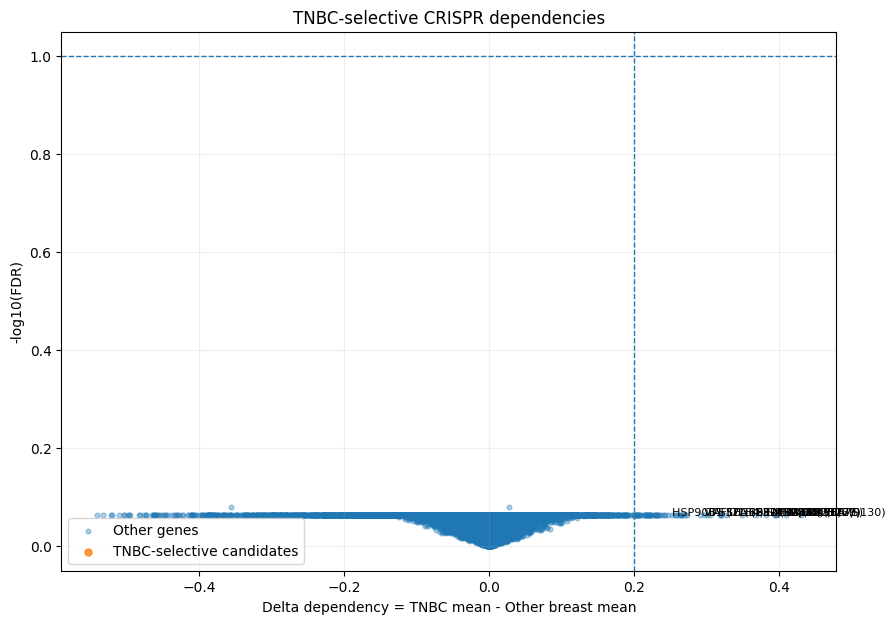

In [ ]:
import matplotlib.pyplot as plt

plot_df = result_df.copy()
plot_df['minus_log10_FDR'] = -np.log10(plot_df['FDR'].clip(lower=1e-300))
plot_df['candidate'] = (
    (plot_df['FDR'] < FDR_CUTOFF) &
    (plot_df['TNBC_mean'] >= TNBC_MEAN_CUTOFF) &
    (plot_df['Delta_dependency'] >= DELTA_CUTOFF) &
    (plot_df['TNBC_dep_fraction'] >= TNBC_FRACTION_CUTOFF)
)

plt.figure(figsize=(10, 7))
plt.scatter(
    plot_df.loc[~plot_df['candidate'], 'Delta_dependency'],
    plot_df.loc[~plot_df['candidate'], 'minus_log10_FDR'],
    s=12, alpha=0.35, label='Other genes'
)
plt.scatter(
    plot_df.loc[plot_df['candidate'], 'Delta_dependency'],
    plot_df.loc[plot_df['candidate'], 'minus_log10_FDR'],
    s=25, alpha=0.8, label='TNBC-selective candidates'
)

plt.axvline(DELTA_CUTOFF, linestyle='--', linewidth=1)
plt.axhline(-np.log10(FDR_CUTOFF), linestyle='--', linewidth=1)
plt.xlabel('Delta dependency = TNBC mean - Other breast mean')
plt.ylabel('-log10(FDR)')
plt.title('TNBC-selective CRISPR dependencies')
plt.legend()
plt.grid(alpha=0.2)

# 상위 후보 label
for _, row in candidate_df.head(10).iterrows():
    y = -np.log10(max(row['FDR'], 1e-300))
    plt.text(row['Delta_dependency'], y, str(row['Gene']), fontsize=8)

plt.show()


# 9. Top candidate heatmap

상위 후보 유전자의 dependency probability를 개별 cell line 수준에서 확인합니다. 평균값만 보는 것보다, 특정 몇 개 cell line이 결과를 주도하는지 확인하는 것이 중요합니다.


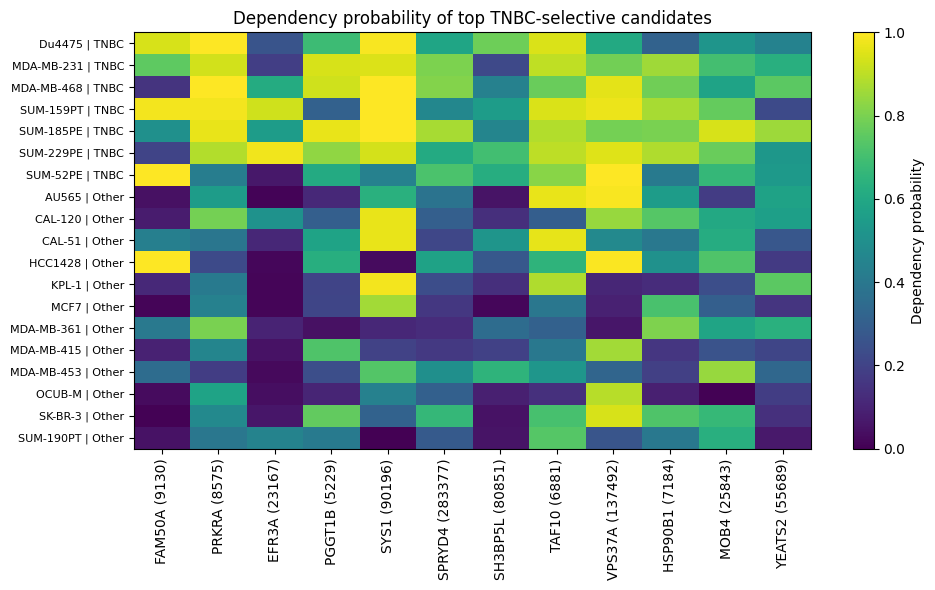

In [ ]:
top_n = min(20, len(candidate_df))

if top_n == 0:
    print('현재 cutoff를 만족하는 candidate가 없습니다. cutoff를 완화하거나 annotation을 확인하세요.')
else:
    top_genes = candidate_df.head(top_n)['Gene'].tolist()
    ordered_meta = breast_cancer_cell_df.sort_values(['TNBC', name_col], ascending=[False, True]).copy()
    ordered_ids = ordered_meta['ModelID'].tolist()

    heat = ess_prob_df.loc[ordered_ids, top_genes]

    fig, ax = plt.subplots(figsize=(max(10, top_n * 0.6), max(6, len(ordered_ids) * 0.28)))
    im = ax.imshow(heat.values, aspect='auto', vmin=0, vmax=1)
    ax.set_xticks(range(len(top_genes)))
    ax.set_xticklabels(top_genes, rotation=90)
    labels = [
        f"{n} | {'TNBC' if t else 'Other'}"
        for n, t in zip(ordered_meta[name_col], ordered_meta['TNBC'])
    ]
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_title('Dependency probability of top TNBC-selective candidates')
    fig.colorbar(im, ax=ax, label='Dependency probability')
    plt.tight_layout()
    plt.show()


# 10. 특정 후보 유전자 자세히 보기

상위 후보 하나를 선택하여 TNBC와 other breast에서 분포를 직접 비교합니다.


/tmp/ipykernel_735/3043241960.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([tnbc_values, other_values], labels=['TNBC', 'Other breast'], showfliers=True)


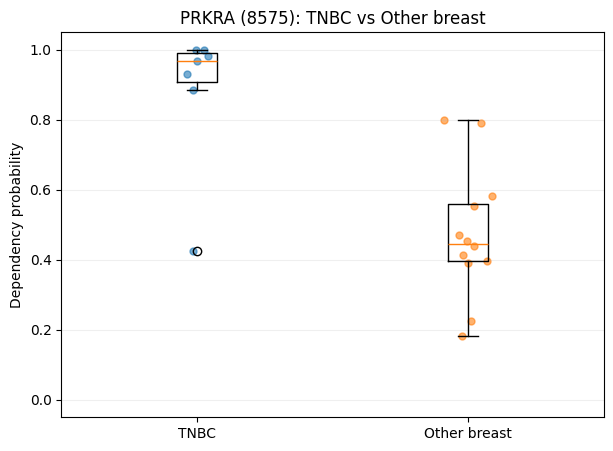

,Gene,TNBC_N,Other_N,TNBC_mean,Other_mean,Delta_dependency,TNBC_dep_fraction,Other_dep_fraction,t_stat,p_value,FDR
1,PRKRA (8575),7,12,0.884148,0.474464,0.409684,0.857143,0.333333,4.299063,0.001095,0.862511


In [ ]:
if len(candidate_df) > 0:
    gene_of_interest = candidate_df.iloc[1]['Gene'] # PRKRA geme

    tnbc_values = ess_prob_df.loc[tnbc_ids, gene_of_interest].dropna()
    other_values = ess_prob_df.loc[other_ids, gene_of_interest].dropna()

    plt.figure(figsize=(7, 5))
    plt.boxplot([tnbc_values, other_values], labels=['TNBC', 'Other breast'], showfliers=True)
    plt.scatter(np.random.normal(1, 0.04, len(tnbc_values)), tnbc_values, alpha=0.6, s=25)
    plt.scatter(np.random.normal(2, 0.04, len(other_values)), other_values, alpha=0.6, s=25)
    plt.ylabel('Dependency probability')
    plt.title(f'{gene_of_interest}: TNBC vs Other breast')
    plt.ylim(-0.05, 1.05)
    plt.grid(axis='y', alpha=0.2)
    plt.show()

    display(candidate_df[candidate_df['Gene'].eq(gene_of_interest)])


# 11. 결과 저장


In [ ]:
result_df.to_csv('TNBC_vs_other_breast_all_genes.csv', index=False)
candidate_df.to_csv('TNBC_selective_target_candidates.csv', index=False)
breast_cancer_cell_df.to_csv('breast_TNBC_annotation_used_in_tutorial.csv', index=False)

print('Saved:')
print('- TNBC_vs_other_breast_all_genes.csv')
print('- TNBC_selective_target_candidates.csv')
print('- breast_TNBC_annotation_used_in_tutorial.csv')


Saved:
- TNBC_vs_other_breast_all_genes.csv
- TNBC_selective_target_candidates.csv
- breast_TNBC_annotation_used_in_tutorial.csv
